In [ ]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv(
    "online_retail_II.csv",
    encoding="ISO-8859-1"
)


In [3]:
print(df.head())

  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1  536365     71053                  WHITE METAL LANTERN         6   
2  536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3  536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4  536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

    InvoiceDate  Price  Customer ID         Country  
0  12/1/10 8:26   2.55      17850.0  United Kingdom  
1  12/1/10 8:26   3.39      17850.0  United Kingdom  
2  12/1/10 8:26   2.75      17850.0  United Kingdom  
3  12/1/10 8:26   3.39      17850.0  United Kingdom  
4  12/1/10 8:26   3.39      17850.0  United Kingdom  


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (541910, 8)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None


In [6]:
print(df.isnull().sum())

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64


In [7]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%y %H:%M"
)


In [8]:
print("First date:", df["InvoiceDate"].min())
print("Last date:", df["InvoiceDate"].max())

First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


In [9]:
print("Unique customers:", df["Customer ID"].nunique())

Unique customers: 4372


In [10]:

df = df.dropna(subset=["Customer ID"]).copy()


df["Invoice"] = df["Invoice"].astype(str)


df = df[~df["Invoice"].str.startswith("C")]


df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
]


df["Sales"] = df["Quantity"] * df["Price"]


print("Cleaned rows:", len(df))
print("Customers:", df["Customer ID"].nunique())

print(df.head())

Cleaned rows: 397885
Customers: 4338
  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1  536365     71053                  WHITE METAL LANTERN         6   
2  536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3  536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4  536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  Price  Customer ID         Country  Sales  
0 2010-12-01 08:26:00   2.55      17850.0  United Kingdom  15.30  
1 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  20.34  
2 2010-12-01 08:26:00   2.75      17850.0  United Kingdom  22.00  
3 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  20.34  
4 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  20.34  


In [11]:

reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

last_purchase = df.groupby("Customer ID")["InvoiceDate"].max()


frequency = df.groupby("Customer ID")["Invoice"].nunique()


monetary = df.groupby("Customer ID")["Sales"].sum()


recency = (reference_date - last_purchase).dt.days


rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
}).reset_index()


print(rfm.head())
print("RFM table shape:", rfm.shape)

   Customer ID  Recency  Frequency  Monetary
0      12346.0      326          1  77183.60
1      12347.0        2          7   4310.00
2      12348.0       75          4   1797.24
3      12349.0       19          1   1757.55
4      12350.0      310          1    334.40
RFM table shape: (4338, 4)


       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2054.27
std     100.01       7.70    8989.23
min       1.00       1.00       3.75
25%      18.00       1.00     307.41
50%      51.00       2.00     674.48
75%     142.00       5.00    1661.74
max     374.00     209.00  280206.02


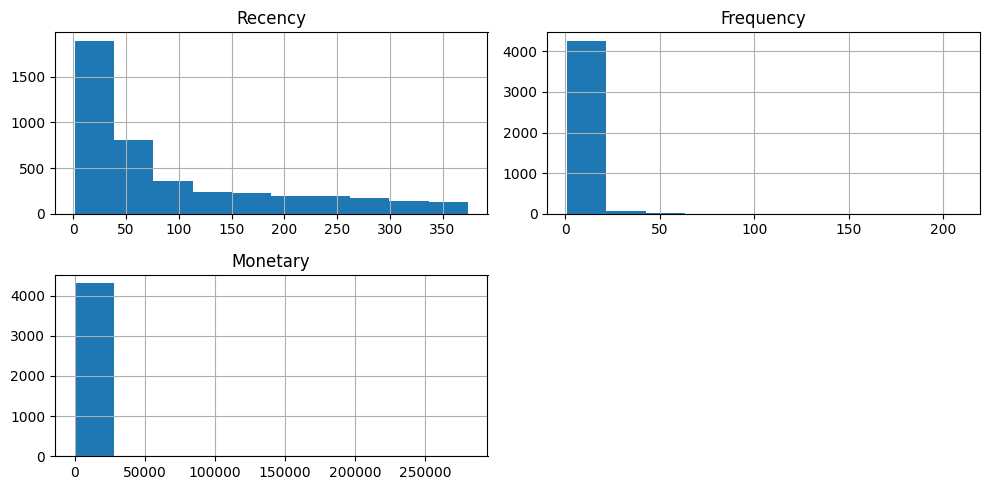

In [13]:

print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(10, 5)
)

plt.tight_layout()
plt.show()

In [15]:

X = rfm[["Recency", "Frequency", "Monetary"]]


X_log = np.log1p(X)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


In [16]:

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)


rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)


print(rfm["KMeans_Cluster"].value_counts().sort_index())


print(
    rfm.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].median().round(2)
)

KMeans_Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64
                Recency  Frequency  Monetary
KMeans_Cluster                              
0                  17.0        2.0    471.70
1                   8.0       10.0   3733.87
2                  56.0        4.0   1345.62
3                 177.0        1.0    298.26


In [17]:

dbscan = DBSCAN(
    eps=0.4,
    min_samples=10
)


rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)


print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

print(
    rfm.groupby("DBSCAN_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].median().round(2)
)

DBSCAN_Cluster
-1     169
 0    1885
 1    1464
 2     820
Name: count, dtype: int64
                Recency  Frequency  Monetary
DBSCAN_Cluster                              
-1                 15.0        9.0   7194.30
 0                 24.0        5.0   1601.14
 1                134.0        1.0    258.36
 2                 62.0        2.0    547.07


In [18]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


variance = pca.explained_variance_ratio_.sum() * 100

print("Variance explained by two components:", round(variance, 2), "%")
print("PCA data shape:", X_pca.shape)

Variance explained by two components: 93.86 %
PCA data shape: (4338, 2)


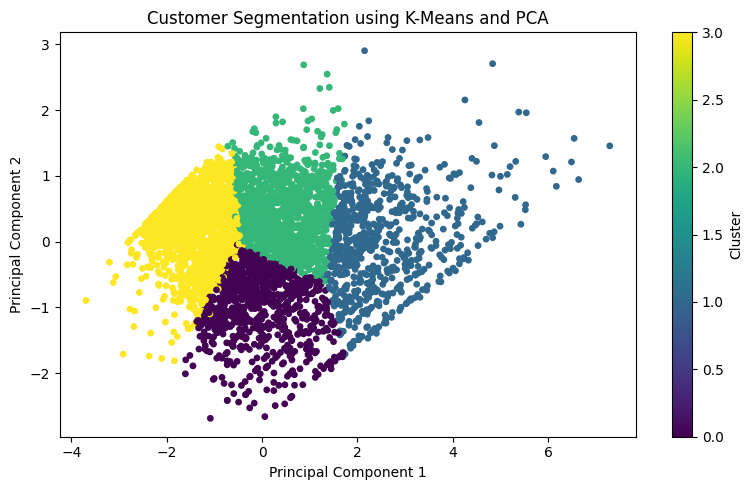

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using K-Means and PCA")
plt.colorbar(label="Cluster")

plt.tight_layout()
plt.show()

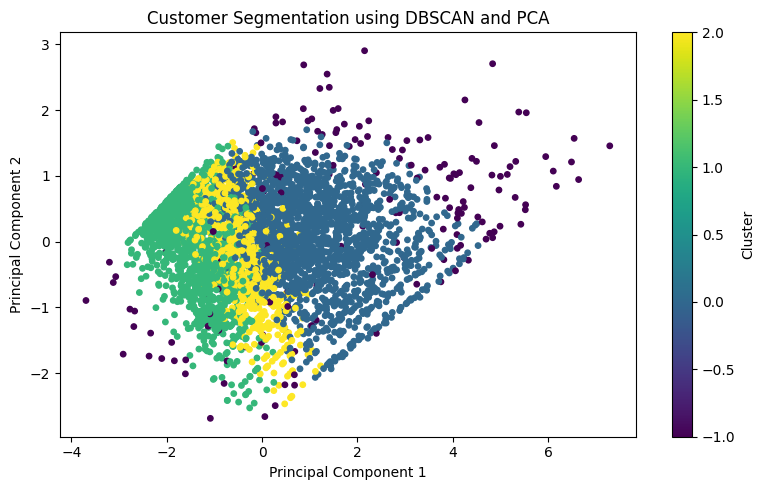

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["DBSCAN_Cluster"],
    cmap="viridis",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using DBSCAN and PCA")
plt.colorbar(label="Cluster")

plt.tight_layout()
plt.show()